In [ ]:
!pip install -q datasets pandas matplotlib seaborn scikit-learn scipy tqdm beautifulsoup4

In [ ]:
import sys, os, random, platform
import numpy as np, pandas as pd, torch, torchvision, sklearn, scipy

SEMENTE = 42
random.seed(SEMENTE); np.random.seed(SEMENTE)
torch.manual_seed(SEMENTE); torch.cuda.manual_seed_all(SEMENTE)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

os.makedirs("/content/saidas", exist_ok=True)
linhas = [
    f"Python: {sys.version.split()[0]}",
    f"PyTorch: {torch.__version__}",
    f"torchvision: {torchvision.__version__}",
    f"NumPy: {np.__version__}",
    f"pandas: {pd.__version__}",
    f"scikit-learn: {sklearn.__version__}",
    f"SciPy: {scipy.__version__}",
    f"GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'nenhuma'}",
    f"Seed: {SEMENTE}",
]
print("\n".join(linhas))
open("/content/saidas/versoes.txt", "w").write("\n".join(linhas))

Python: 3.13.16
PyTorch: 2.11.0+cu130
torchvision: 0.26.0+cu130
NumPy: 2.4.6
pandas: 2.2.3
scikit-learn: 1.6.1
SciPy: 1.16.3
GPU: Tesla T4
Seed: 42


147

In [ ]:
from datasets import load_dataset

ds = load_dataset("harvardairobotics/FairVision", "dr")
df = ds["train"].to_pandas()
print(df.shape)
print(df.isnull().sum())
print(df["dr"].value_counts())
print(df["use"].value_counts())
print(df["race"].value_counts())
display(df.head())

README.md:   0%|          | 0.00/5.53k [00:00<?, ?B/s]

data_summary_dr.csv:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/10000 [00:00<?, ? examples/s]

(10000, 9)
filename         0
age              0
gender           0
race             0
ethnicity        0
language         0
maritalstatus    0
dr               0
use              0
dtype: int64
dr
non-vision threatening dr    9091
vision threatening dr         909
Name: count, dtype: int64
use
training      6000
test          3000
validation    1000
Name: count, dtype: int64
race
white    7779
black    1457
asian     764
Name: count, dtype: int64


,filename,age,gender,race,ethnicity,language,maritalstatus,dr,use
0,data_00001.npz,62.93,female,white,non-hispanic,english,married or partnered,non-vision threatening dr,training
1,data_00002.npz,76.80,female,black,non-hispanic,english,married or partnered,non-vision threatening dr,training
2,data_00003.npz,63.74,male,white,non-hispanic,english,married or partnered,non-vision threatening dr,training
3,data_00004.npz,94.70,male,white,non-hispanic,english,married or partnered,non-vision threatening dr,training
4,data_00005.npz,75.72,female,white,non-hispanic,english,married or partnered,non-vision threatening dr,training


In [ ]:
import requests
from bs4 import BeautifulSoup

FILE_ID = "16UWfi8Px6WFVwOJtILwygUHnARb3ztZ5"
r = requests.get(f"https://drive.google.com/uc?export=download&id={FILE_ID}")
form = BeautifulSoup(r.text, "html.parser").find("form")
URL = form.get("action")
PARAMS = {i.get("name"): i.get("value") for i in form.find_all("input") if i.get("name")}

t = requests.get(URL, params=PARAMS, headers={"Range": "bytes=0-0"})
print("Status:", t.status_code)
TAMANHO = int(t.headers["Content-Range"].split("/")[1])
print("Tamanho do ZIP:", TAMANHO)

Status: 206
Tamanho do ZIP: 39841609539


In [ ]:
import time, zipfile

class LeitorZipRemoto:
    def __init__(self, url, params, tamanho):
        self.url, self.params, self.tamanho = url, params, tamanho
        self.pos = 0
        self.s = requests.Session()
    def seek(self, off, whence=0):
        if whence == 0: self.pos = off
        elif whence == 1: self.pos += off
        else: self.pos = self.tamanho + off
        return self.pos
    def tell(self): return self.pos
    def seekable(self): return True
    def readable(self): return True
    def read(self, n=-1):
        if n is None or n < 0: n = self.tamanho - self.pos
        fim = min(self.pos + n, self.tamanho)
        if self.pos >= fim: return b""
        for t in range(6):
            try:
                r = self.s.get(self.url, params=self.params,
                               headers={"Range": f"bytes={self.pos}-{fim-1}"},
                               timeout=(15, 60))
                if r.status_code == 206 and len(r.content) == fim - self.pos:
                    self.pos = fim
                    return r.content
                raise Exception(f"HTTP {r.status_code}")
            except Exception:
                time.sleep(2 ** t)
        raise Exception("Falha após 6 tentativas")

zip_remoto = zipfile.ZipFile(LeitorZipRemoto(URL, PARAMS, TAMANHO))
jpg_files = [n for n in zip_remoto.namelist()
             if n.lower().endswith(".jpg") and "__macosx" not in n.lower()]
print("JPGs no ZIP:", len(jpg_files))
print(jpg_files[:3])

JPGs no ZIP: 10000
['Test/slo_fundus_09382.jpg', 'Test/slo_fundus_08922.jpg', 'Test/slo_fundus_08936.jpg']


In [ ]:
import threading
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.auto import tqdm

PASTA_LOCAL = "/content/slo"
os.makedirs(PASTA_LOCAL, exist_ok=True)
_local = threading.local()

def baixar(caminho):
    destino = os.path.join(PASTA_LOCAL, os.path.basename(caminho))
    if os.path.exists(destino) and os.path.getsize(destino) > 0:
        return
    if not hasattr(_local, "zip"):
        _local.zip = zipfile.ZipFile(LeitorZipRemoto(URL, PARAMS, TAMANHO))
    dados = _local.zip.read(caminho)
    with open(destino + ".tmp", "wb") as f:
        f.write(dados)
    os.replace(destino + ".tmp", destino)

falhas = []
with ThreadPoolExecutor(max_workers=8) as ex:
    futuros = {ex.submit(baixar, c): c for c in jpg_files}
    for fut in tqdm(as_completed(futuros), total=len(futuros)):
        try: fut.result()
        except Exception as e: falhas.append((futuros[fut], str(e)))

print("Baixadas:", len(os.listdir(PASTA_LOCAL)), "| Falhas:", len(falhas))

  0%|          | 0/10000 [00:00<?, ?it/s]

Baixadas: 10000 | Falhas: 0


In [ ]:
df_modelo = df.copy()
df_modelo["id"] = df_modelo["filename"].str.replace("data_", "", regex=False).str.replace(".npz", "", regex=False)

caminho_por_id = {os.path.basename(c).replace("slo_fundus_", "").replace(".jpg", ""): c
                  for c in jpg_files}
df_modelo["image_path"] = df_modelo["id"].map(caminho_por_id)

# Mapeamento do rótulo (decisão metodológica, vai para o artigo)
mapa_rotulos = {"non-vision threatening dr": 0, "vision threatening dr": 1}
df_modelo["label"] = df_modelo["dr"].map(mapa_rotulos)

print("Sem imagem:", df_modelo["image_path"].isna().sum())
print("Sem rótulo:", df_modelo["label"].isna().sum())
print("Divisão do metadado x pasta da imagem inconsistentes:",
      (df_modelo["use"] != df_modelo["image_path"].str.split("/").str[0].str.lower()).sum())
print(df_modelo["label"].value_counts())

Sem imagem: 0
Sem rótulo: 0
Divisão do metadado x pasta da imagem inconsistentes: 0
label
0    9091
1     909
Name: count, dtype: int64


In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

amostra = df_modelo.sample(3, random_state=SEMENTE)
fig, eixos = plt.subplots(1, 3, figsize=(12, 4))
for eixo, (_, linha) in zip(eixos, amostra.iterrows()):
    img = Image.open(os.path.join(PASTA_LOCAL, os.path.basename(linha["image_path"]))).convert("RGB")
    eixo.imshow(img); eixo.axis("off")
    eixo.set_title(f"{img.size} | label={linha['label']} | {linha['race']}")
plt.show()

In [ ]:
os.makedirs("/content/saidas/tabelas", exist_ok=True)
ordem = ["training", "validation", "test"]

print("VALORES AUSENTES:")
print(df_modelo[["age", "gender", "race", "ethnicity", "language", "label"]].isna().sum())

t1 = pd.crosstab(df_modelo["use"], df_modelo["label"], margins=True).reindex(ordem + ["All"])
t1.columns = ["negativos", "positivos", "total"]
t1["prevalencia_%"] = (t1["positivos"] / t1["total"] * 100).round(2)
display(t1)
t1.to_csv("/content/saidas/tabelas/divisao_x_classe.csv")

VALORES AUSENTES:
age          0
gender       0
race         0
ethnicity    0
language     0
label        0
dtype: int64


,negativos,positivos,total,prevalencia_%
use,,,,
training,5435,565,6000,9.42
validation,917,83,1000,8.30
test,2739,261,3000,8.70
All,9091,909,10000,9.09


In [ ]:
def tabela_grupo(coluna):
    g = df_modelo.groupby(["use", coluna], observed=True)["label"].agg(
        n="count", positivos="sum")
    g["negativos"] = g["n"] - g["positivos"]
    g["prevalencia_%"] = (g["positivos"] / g["n"] * 100).round(2)
    g = g.reset_index()
    g["use"] = pd.Categorical(g["use"], categories=ordem, ordered=True)
    g = g.sort_values(["use", coluna]).reset_index(drop=True)
    g["use"] = g["use"].astype(str)
    total = df_modelo.groupby(coluna)["label"].agg(n="count", positivos="sum")
    total["prevalencia_%"] = (total["positivos"] / total["n"] * 100).round(2)
    return g, total

for col in ["race", "gender", "ethnicity", "language"]:
    por_divisao, total = tabela_grupo(col)
    print(f"\n===== {col.upper()}: por divisão =====")
    display(por_divisao)
    print(f"===== {col.upper()}: total (todas as divisões) =====")
    display(total)
    por_divisao.to_csv(f"/content/saidas/tabelas/{col}_por_divisao.csv", index=False)
    total.to_csv(f"/content/saidas/tabelas/{col}_total.csv")


===== RACE: por divisão =====


,use,race,n,positivos,negativos,prevalencia_%
0,training,asian,452,41,411,9.07
1,training,black,846,119,727,14.07
2,training,white,4702,405,4297,8.61
3,validation,asian,79,2,77,2.53
4,validation,black,159,21,138,13.21
5,validation,white,762,60,702,7.87
6,test,asian,233,16,217,6.87
7,test,black,452,59,393,13.05
8,test,white,2315,186,2129,8.03


===== RACE: total (todas as divisões) =====


,n,positivos,prevalencia_%
race,,,
asian,764,59,7.72
black,1457,199,13.66
white,7779,651,8.37



===== GENDER: por divisão =====


,use,gender,n,positivos,negativos,prevalencia_%
0,training,female,3328,255,3073,7.66
1,training,male,2672,310,2362,11.60
2,validation,female,560,42,518,7.50
3,validation,male,440,41,399,9.32
4,test,female,1665,118,1547,7.09
5,test,male,1335,143,1192,10.71


... (6 outputs left out)


===== LANGUAGE: por divisão =====


,use,language,n,positivos,negativos,prevalencia_%
0,training,english,5456,485,4971,8.89
1,training,other languages,426,57,369,13.38
2,training,spanish,118,23,95,19.49
3,validation,english,914,77,837,8.42
4,validation,other languages,64,5,59,7.81
5,validation,spanish,22,1,21,4.55
6,test,english,2722,232,2490,8.52
7,test,other languages,215,22,193,10.23
8,test,spanish,63,7,56,11.11


===== LANGUAGE: total (todas as divisões) =====


,n,positivos,prevalencia_%
language,,,
english,9092,794,8.73
other languages,705,84,11.91
spanish,203,31,15.27


In [ ]:
for col in ["race", "gender"]:
    print(f"\nIDADE POR {col.upper()}:")
    display(df_modelo.groupby(col)["age"].describe().round(1))
df_modelo.groupby("label")["age"].describe().round(1).to_csv("/content/saidas/tabelas/idade_por_classe.csv")
df_modelo.groupby("race")["age"].describe().round(1).to_csv("/content/saidas/tabelas/idade_por_raca.csv")


IDADE POR RACE:


,count,mean,std,min,25%,50%,75%,max
race,,,,,,,,
asian,764.0,60.5,17.2,11.2,49.3,63.2,73.6,99.6
black,1457.0,61.1,15.4,11.5,51.9,62.8,72.2,98.2
white,7779.0,65.5,16.5,3.9,57.9,68.5,76.5,102.4



IDADE POR GENDER:


,count,mean,std,min,25%,50%,75%,max
gender,,,,,,,,
female,5553.0,64.7,17.0,6.2,56.0,67.8,76.3,102.4
male,4447.0,64.3,15.8,3.9,56.6,67.0,75.1,101.2


In [ ]:
teste = df_modelo[df_modelo["use"] == "test"]
for col in ["race", "gender", "ethnicity", "language"]:
    print(f"\nTESTE por {col}:")
    display(teste.groupby(col)["label"].agg(n="count", positivos="sum"))


TESTE por race:


,n,positivos
race,,
asian,233,16
black,452,59
white,2315,186



TESTE por gender:


,n,positivos
gender,,
female,1665,118
male,1335,143



TESTE por ethnicity:


,n,positivos
ethnicity,,
hispanic,113,15
non-hispanic,2887,246



TESTE por language:


,n,positivos
language,,
english,2722,232
other languages,215,22
spanish,63,7


In [ ]:
particoes = {n: df_modelo[df_modelo["use"] == n] for n in ordem}
ids = {n: set(p["id"]) for n, p in particoes.items()}

print("IDs únicos / total:", df_modelo["id"].nunique(), "/", len(df_modelo))
print("treino ∩ validação:", len(ids["training"] & ids["validation"]))
print("treino ∩ teste:    ", len(ids["training"] & ids["test"]))
print("validação ∩ teste: ", len(ids["validation"] & ids["test"]))

assert df_modelo["id"].is_unique
assert not (ids["training"] & ids["validation"])
assert not (ids["training"] & ids["test"])
assert not (ids["validation"] & ids["test"])
print("\nVERIFICAÇÃO PASSOU: nenhuma interseção entre as partições.")

total = len(df_modelo)
print("\nPROPORÇÕES REAIS:")
for n in ordem:
    print(f"{n}: {len(particoes[n])} ({len(particoes[n]) / total * 100:.1f}%)")

os.makedirs("/content/saidas/splits", exist_ok=True)
for n in ordem:
    particoes[n][["id", "filename", "label", "race", "gender", "ethnicity", "age"]].to_csv(
        f"/content/saidas/splits/{n}.csv", index=False)
print("\nListas salvas em /content/saidas/splits/")

IDs únicos / total: 10000 / 10000
treino ∩ validação: 0
treino ∩ teste:     0
validação ∩ teste:  0

VERIFICAÇÃO PASSOU: nenhuma interseção entre as partições.

PROPORÇÕES REAIS:
training: 6000 (60.0%)
validation: 1000 (10.0%)
test: 3000 (30.0%)

Listas salvas em /content/saidas/splits/


In [ ]:
import numpy as np, os
from PIL import Image
from tqdm.auto import tqdm

TAM = 224
os.makedirs("/content/cache", exist_ok=True)

def carregar(caminho):
    img = Image.open(os.path.join(PASTA_LOCAL, os.path.basename(caminho))).convert("RGB")
    return np.asarray(img.resize((TAM, TAM), Image.BILINEAR), dtype=np.uint8)

invalidas = []
for n in ordem:
    p = particoes[n].reset_index(drop=True)
    X = np.zeros((len(p), TAM, TAM, 3), dtype=np.uint8)
    for i, c in enumerate(tqdm(p["image_path"], desc=n)):
        try:
            X[i] = carregar(c)
        except Exception as e:
            invalidas.append((n, c, str(e)))
    np.save(f"/content/cache/{n}_X.npy", X)
    np.save(f"/content/cache/{n}_y.npy", p["label"].values.astype(np.int64))
    p.to_csv(f"/content/cache/{n}_meta.csv", index=False)

print("Imagens inválidas:", len(invalidas))

training:   0%|          | 0/6000 [00:00<?, ?it/s]

validation:   0%|          | 0/1000 [00:00<?, ?it/s]

test:   0%|          | 0/3000 [00:00<?, ?it/s]

Imagens inválidas: 0


In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.v2 as T

MEDIA, DP = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
BATCH = 32

aug_treino = T.Compose([
    T.RandomHorizontalFlip(0.5),
    T.RandomRotation(10),
    T.ColorJitter(brightness=0.1, contrast=0.1),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(MEDIA, DP),
])
sem_aug = T.Compose([T.ToDtype(torch.float32, scale=True), T.Normalize(MEDIA, DP)])

class SLO(Dataset):
    def __init__(self, nome, transf):
        self.X = np.load(f"/content/cache/{nome}_X.npy", mmap_mode="r")
        self.y = np.load(f"/content/cache/{nome}_y.npy")
        self.meta = pd.read_csv(f"/content/cache/{nome}_meta.csv")
        self.t = transf
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        x = torch.from_numpy(np.array(self.X[i])).permute(2, 0, 1)
        return self.t(x), self.y[i], i

dados = {"training": SLO("training", aug_treino),
         "validation": SLO("validation", sem_aug),
         "test": SLO("test", sem_aug)}
loaders = {n: DataLoader(d, batch_size=BATCH, shuffle=(n == "training"), num_workers=2)
           for n, d in dados.items()}

x, y, _ = next(iter(loaders["training"]))
print(x.shape, x.dtype, y[:8], x.mean().item(), x.std().item())

torch.Size([32, 3, 224, 224]) torch.float32 tensor([0, 0, 0, 0, 0, 0, 0, 0]) -1.4375221729278564 0.4559445083141327


In [ ]:
import matplotlib.pyplot as plt
mean, std = torch.tensor(MEDIA)[:, None, None], torch.tensor(DP)[:, None, None]
fig, ax = plt.subplots(1, 4, figsize=(14, 4))
for k in range(4):
    ax[k].imshow((x[k] * std + mean).clamp(0, 1).permute(1, 2, 0))
    ax[k].set_title(f"label={y[k].item()}"); ax[k].axis("off")
plt.savefig("/content/saidas/lote_conferencia.png", dpi=120); plt.show()

In [ ]:
import time, json, torch.nn as nn
from sklearn.metrics import roc_auc_score

dev = "cuda"
meta_tr = dados["training"].meta
y_tr = meta_tr["label"].values
N, LIMITE = len(y_tr), 10.0

# Baseline: inverso da frequência da classe (média dos pesos = 1)
cnt = np.bincount(y_tr)
w_base = (N / (2 * cnt))[y_tr]

# Mitigado: inverso da frequência de cada célula raça x classe, com teto
cel = meta_tr["race"] + "_" + meta_tr["label"].astype(str)
cnt_cel = cel.value_counts()
w_mit_bruto = N / (len(cnt_cel) * cel.map(cnt_cel).values)
w_mit = np.clip(w_mit_bruto, None, LIMITE)

tab = pd.DataFrame({"celula": cel, "peso_bruto": w_mit_bruto, "peso_usado": w_mit}).drop_duplicates().sort_values("celula")
display(tab); print("média baseline:", w_base.mean(), "| média mitigado (após teto):", w_mit.mean())
tab.to_csv("/content/saidas/tabelas/pesos_mitigado.csv", index=False)

,celula,peso_bruto,peso_usado
18,asian_0,2.433090,2.433090
157,asian_1,24.390244,10.000000
1,black_0,1.375516,1.375516
66,black_1,8.403361,8.403361
0,white_0,0.232721,0.232721
24,white_1,2.469136,2.469136


média baseline: 1.0 | média mitigado (após teto): 0.9016666666666666


In [ ]:
os.makedirs("/content/models", exist_ok=True)
lossf = nn.BCEWithLogitsLoss(reduction="none")

@torch.no_grad()
def avaliar(model, loader):
    model.eval(); ps, ys, ls = [], [], []
    for x, y, _ in loader:
        x, y = x.to(dev), y.float().to(dev)
        with torch.autocast("cuda"):
            o = model(x).squeeze(1)
        ls.append(lossf(o.float(), y).cpu()); ps.append(torch.sigmoid(o.float()).cpu()); ys.append(y.cpu())
    ps, ys = torch.cat(ps).numpy(), torch.cat(ys).numpy()
    return roc_auc_score(ys, ps), torch.cat(ls).mean().item()

def treinar(nome, w_amostra, max_ep=20, pac=5, lr=1e-4):
    torch.manual_seed(SEMENTE); np.random.seed(SEMENTE); random.seed(SEMENTE)
    model = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(512, 1); model.to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    scaler = torch.amp.GradScaler()
    w_t = torch.tensor(w_amostra, dtype=torch.float32, device=dev)
    log, melhor, melhor_ep, sem_melhora, t0 = [], -1, 0, 0, time.time()
    for ep in range(1, max_ep + 1):
        te = time.time(); model.train(); ls, ps, ys = [], [], []
        for x, y, idx in loaders["training"]:
            x, y, w = x.to(dev), y.float().to(dev), w_t[idx.to(dev)]
            opt.zero_grad()
            with torch.autocast("cuda"):
                o = model(x).squeeze(1)
            loss = (lossf(o.float(), y) * w).mean()
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            ls.append(loss.item()); ps.append(torch.sigmoid(o.float()).detach().cpu()); ys.append(y.cpu())
        auc_tr = roc_auc_score(torch.cat(ys).numpy(), torch.cat(ps).numpy())
        auc_va, loss_va = avaliar(model, loaders["validation"])
        log.append(dict(epoca=ep, loss_treino=np.mean(ls), auroc_treino=auc_tr,
                        loss_val=loss_va, auroc_val=auc_va, seg=time.time() - te))
        print(log[-1])
        if auc_va > melhor:
            melhor, melhor_ep, sem_melhora = auc_va, ep, 0
            torch.save(model.state_dict(), f"/content/models/{nome}.pt")
        else:
            sem_melhora += 1
            if sem_melhora >= pac: break
    total = time.time() - t0
    pd.DataFrame(log).to_csv(f"/content/saidas/log_{nome}.csv", index=False)
    resumo = dict(modelo=nome, epocas_executadas=len(log), melhor_epoca=melhor_ep,
                  melhor_auroc_val=melhor, tempo_total_s=round(total, 1))
    json.dump(resumo, open(f"/content/saidas/resumo_{nome}.json", "w")); print(resumo)
    return log, resumo

In [ ]:
log_base, res_base = treinar("baseline", w_base)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 76.5MB/s]


{'epoca': 1, 'loss_treino': np.float64(0.5967411926769196), 'auroc_treino': np.float64(0.7562555055319912), 'loss_val': 0.437767893075943, 'auroc_val': np.float64(0.8151975404343655), 'seg': 28.482820987701416}
{'epoca': 2, 'loss_treino': np.float64(0.540743665650804), 'auroc_treino': np.float64(0.8016963144483069), 'loss_val': 0.5812349915504456, 'auroc_val': np.float64(0.7875011496367149), 'seg': 28.02270793914795}
{'epoca': 3, 'loss_treino': np.float64(0.48335061951520597), 'auroc_treino': np.float64(0.8470902296651497), 'loss_val': 0.3742828369140625, 'auroc_val': np.float64(0.8156771031782528), 'seg': 27.14393973350525}
{'epoca': 4, 'loss_treino': np.float64(0.4429994001984596), 'auroc_treino': np.float64(0.8760895865050353), 'loss_val': 0.5371745824813843, 'auroc_val': np.float64(0.8217209076217631), 'seg': 25.7628071308136}
{'epoca': 5, 'loss_treino': np.float64(0.4024104716137369), 'auroc_treino': np.float64(0.8967068573894212), 'loss_val': 0.45225298404693604, 'auroc_val': np.

In [ ]:
log_mit, res_mit = treinar("mitigado", w_mit)

{'epoca': 1, 'loss_treino': np.float64(0.568984736311943), 'auroc_treino': np.float64(0.7130035577337968), 'loss_val': 0.6662992238998413, 'auroc_val': np.float64(0.7190484949613065), 'seg': 29.651758670806885}
{'epoca': 2, 'loss_treino': np.float64(0.5094035743398869), 'auroc_treino': np.float64(0.7718846219602543), 'loss_val': 0.4534190595149994, 'auroc_val': np.float64(0.7858456727674055), 'seg': 27.017259120941162}
{'epoca': 3, 'loss_treino': np.float64(0.4564024141018695), 'auroc_treino': np.float64(0.8141631998436876), 'loss_val': 0.43810537457466125, 'auroc_val': np.float64(0.7915215934621802), 'seg': 26.8500235080719}
{'epoca': 4, 'loss_treino': np.float64(0.42316297326791796), 'auroc_treino': np.float64(0.8386058893927428), 'loss_val': 0.3455907702445984, 'auroc_val': np.float64(0.7956602856354534), 'seg': 26.067670583724976}
{'epoca': 5, 'loss_treino': np.float64(0.3852218332839139), 'auroc_treino': np.float64(0.8545570743541939), 'loss_val': 0.34294718503952026, 'auroc_val':

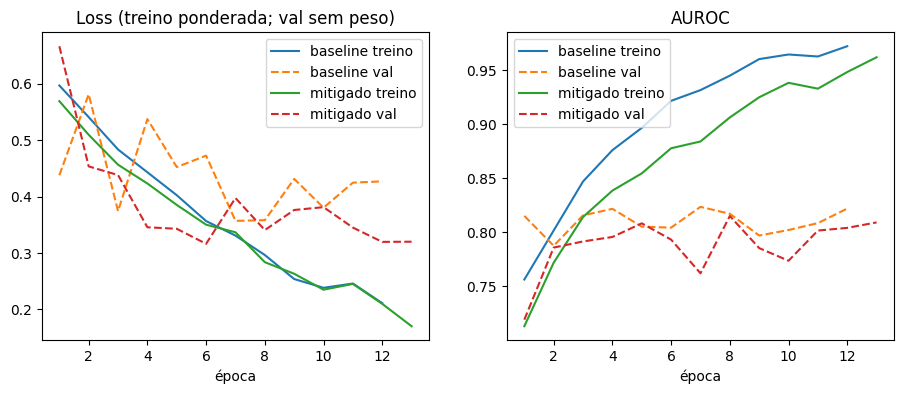

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for nome, lg in [("baseline", log_base), ("mitigado", log_mit)]:
    d = pd.DataFrame(lg)
    ax[0].plot(d.epoca, d.loss_treino, label=f"{nome} treino"); ax[0].plot(d.epoca, d.loss_val, "--", label=f"{nome} val")
    ax[1].plot(d.epoca, d.auroc_treino, label=f"{nome} treino"); ax[1].plot(d.epoca, d.auroc_val, "--", label=f"{nome} val")
ax[0].set_title("Loss (treino ponderada; val sem peso)"); ax[1].set_title("AUROC")
for a in ax: a.set_xlabel("época"); a.legend()
plt.savefig("/content/saidas/curvas_treino.png", dpi=130); plt.show()

In [ ]:
from sklearn.metrics import roc_curve

@torch.no_grad()
def probs(model, loader):
    model.eval(); ps = []
    for x, y, _ in loader:
        with torch.autocast("cuda"):
            ps.append(torch.sigmoid(model(x.to(dev)).squeeze(1).float()).cpu())
    return torch.cat(ps).numpy()

limiares = {}
y_va = dados["validation"].y
for nome in ["baseline", "mitigado"]:
    m = torchvision.models.resnet18(); m.fc = nn.Linear(512, 1)
    m.load_state_dict(torch.load(f"/content/models/{nome}.pt")); m.to(dev)
    p = probs(m, loaders["validation"])
    fpr, tpr, thr = roc_curve(y_va, p)
    k = (tpr - fpr).argmax()
    limiares[nome] = dict(limiar=float(thr[k]), tpr_val=float(tpr[k]), fpr_val=float(fpr[k]))
    print(nome, limiares[nome])
json.dump(limiares, open("/content/saidas/limiares.json", "w"), indent=2)

baseline {'limiar': 0.113973468542099, 'tpr_val': 0.8674698795180723, 'fpr_val': 0.35223555070883317}
mitigado {'limiar': 0.3051794171333313, 'tpr_val': 0.7228915662650602, 'fpr_val': 0.23991275899672845}


In [ ]:
from sklearn.metrics import (roc_auc_score, confusion_matrix, precision_score, f1_score)

limiares = json.load(open("/content/saidas/limiares.json"))
meta_te = dados["test"].meta.copy()
y_te = dados["test"].y
os.makedirs("/content/saidas/predicoes", exist_ok=True)

resumo_global = {}
for nome in ["baseline", "mitigado"]:
    m = torchvision.models.resnet18(); m.fc = nn.Linear(512, 1)
    m.load_state_dict(torch.load(f"/content/models/{nome}.pt")); m.to(dev)
    p = probs(m, loaders["test"])
    lim = limiares[nome]["limiar"]
    pred = (p >= lim).astype(int)

    out = meta_te[["id", "race", "gender", "ethnicity", "language", "age"]].copy()
    out["y_true"], out["prob"], out["y_pred"] = y_te, p, pred
    out.to_csv(f"/content/saidas/predicoes/teste_{nome}.csv", index=False)

    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    resumo_global[nome] = dict(
        n=len(y_te), positivos=int(y_te.sum()), limiar=lim,
        auroc=roc_auc_score(y_te, p), sensibilidade=tp / (tp + fn),
        especificidade=tn / (tn + fp), precisao=precision_score(y_te, pred),
        f1=f1_score(y_te, pred), TN=int(tn), FP=int(fp), FN=int(fn), TP=int(tp))
    print(nome, resumo_global[nome])

json.dump(resumo_global, open("/content/saidas/teste_global.json", "w"), indent=2)

baseline {'n': 3000, 'positivos': 261, 'limiar': 0.113973468542099, 'auroc': np.float64(0.8037220284831419), 'sensibilidade': np.float64(0.7969348659003831), 'especificidade': np.float64(0.6436655713764148), 'precisao': 0.17567567567567569, 'f1': 0.2878892733564014, 'TN': 1763, 'FP': 976, 'FN': 53, 'TP': 208}
mitigado {'n': 3000, 'positivos': 261, 'limiar': 0.3051794171333313, 'auroc': np.float64(0.7968873054041313), 'sensibilidade': np.float64(0.6781609195402298), 'especificidade': np.float64(0.7356699525374224), 'precisao': 0.19644839067702552, 'f1': 0.3046471600688468, 'TN': 2015, 'FP': 724, 'FN': 84, 'TP': 177}


In [ ]:
from google.colab import drive
drive.mount("/content/drive")
!mkdir -p /content/drive/MyDrive/Artigo3
!cp -r /content/saidas /content/models /content/drive/MyDrive/Artigo3/

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from google.colab import drive
drive.mount("/content/drive")
!mkdir -p /content/drive/MyDrive/Artigo3/saidas
!cp -r /content/saidas/. /content/drive/MyDrive/Artigo3/saidas/
!ls /content/drive/MyDrive/Artigo3/saidas /content/drive/MyDrive/Artigo3/saidas/predicoes

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Artigo3/saidas:
curvas_treino.png  lote_conferencia.png  splits
limiares.json	   predicoes		 tabelas
log_baseline.csv   resumo_baseline.json  teste_global.json
log_mitigado.csv   resumo_mitigado.json  versoes.txt

/content/drive/MyDrive/Artigo3/saidas/predicoes:
teste_baseline.csv  teste_mitigado.csv


In [ ]:
import warnings; warnings.filterwarnings("ignore")
NB = NP = 1000
prd = {n: pd.read_csv(f"/content/saidas/predicoes/teste_{n}.csv") for n in ["baseline", "mitigado"]}
assert (prd["baseline"]["id"] == prd["mitigado"]["id"]).all()
N = len(prd["baseline"])
rng = np.random.default_rng(SEMENTE)
boot_idx = rng.integers(0, N, size=(NB, N))
perm_idx = np.array([rng.permutation(N) for _ in range(NP)])
attrs = {"race": (["white", "black", "asian"], "white"), "gender": (["female", "male"], "female")}

def metricas(y, pred, prob, g, grupos, auc=True):
    out = {}
    for k in grupos:
        m = g == k; yy, pp = y[m], pred[m]
        pos = yy.sum(); neg = len(yy) - pos
        tp = ((pp == 1) & (yy == 1)).sum(); fp = ((pp == 1) & (yy == 0)).sum()
        out[k] = dict(n=int(m.sum()), positivos=int(pos),
                      prev=pos / max(m.sum(), 1),
                      tpr=tp / pos if pos else np.nan,
                      fpr=fp / neg if neg else np.nan,
                      ppv=tp / (tp + fp) if (tp + fp) else np.nan,
                      auc=roc_auc_score(yy, prob[m]) if (auc and 0 < pos < len(yy)) else np.nan)
    return out

def gaps(out, ref):
    t = np.array([v["tpr"] for v in out.values()])
    f = np.array([v["fpr"] for v in out.values()])
    a = np.array([v["auc"] for v in out.values()])
    d = {"dTPR": np.nanmax(t) - np.nanmin(t), "dFPR": np.nanmax(f) - np.nanmin(f),
         "dAUC": np.nanmax(a) - np.nanmin(a)}
    d["equalized_odds"] = np.fmax(d["dTPR"], d["dFPR"])
    for k, v in out.items():
        if k != ref:
            for m in ["tpr", "fpr", "auc"]:
                d[f"{m}_{k}-{ref}"] = v[m] - out[ref][m]
    return d

def ic(vals):
    lo, hi = np.nanpercentile(vals, [2.5, 97.5]); return f"[{lo:.3f}; {hi:.3f}]"

linhas_g, linhas_gap = [], []
for modelo, df in prd.items():
    y, pred, prob = df.y_true.values, df.y_pred.values, df.prob.values
    for attr, (grupos, ref) in attrs.items():
        g = df[attr].values
        obs = metricas(y, pred, prob, g, grupos); og = gaps(obs, ref)
        bm, bg = [], []
        for b in boot_idx:
            o = metricas(y[b], pred[b], prob[b], g[b], grupos); bm.append(o); bg.append(gaps(o, ref))
        pg = [gaps(metricas(y, pred, prob, g[p], grupos, auc=False), ref) for p in perm_idx]
        for k in grupos:
            linhas_g.append(dict(modelo=modelo, atributo=attr, grupo=k, n=obs[k]["n"],
                positivos=obs[k]["positivos"], prevalencia_pct=round(obs[k]["prev"] * 100, 2),
                AUROC=round(obs[k]["auc"], 3), AUROC_IC=ic([x[k]["auc"] for x in bm]),
                TPR=round(obs[k]["tpr"], 3), TPR_IC=ic([x[k]["tpr"] for x in bm]),
                FPR=round(obs[k]["fpr"], 3), FPR_IC=ic([x[k]["fpr"] for x in bm]),
                PPV=round(obs[k]["ppv"], 3)))
        for key, v in og.items():
            pv = np.array([x[key] for x in pg])
            if np.isnan(pv).all(): p = np.nan
            elif key.startswith(("d", "eq")): p = (np.sum(pv >= v) + 1) / (NP + 1)
            else: p = (np.sum(np.abs(pv) >= abs(v)) + 1) / (NP + 1)
            linhas_gap.append(dict(modelo=modelo, atributo=attr, medida=key, valor=round(v, 3),
                IC95=ic([x[key] for x in bg]), p_permutacao=round(p, 3) if p == p else "n/d"))

tab_g, tab_gap = pd.DataFrame(linhas_g), pd.DataFrame(linhas_gap)
tab_g.to_csv("/content/saidas/tabelas/tabela3_por_grupo.csv", index=False)
tab_gap.to_csv("/content/saidas/tabelas/tabela3_gaps.csv", index=False)
pd.set_option("display.width", 250, "display.max_columns", 30)
display(tab_g); display(tab_gap)

,modelo,atributo,grupo,n,positivos,prevalencia_pct,AUROC,AUROC_IC,TPR,TPR_IC,FPR,FPR_IC,PPV
0,baseline,race,white,2315,186,8.03,0.823,[0.792; 0.852],0.796,[0.736; 0.853],0.321,[0.302; 0.342],0.178
1,baseline,race,black,452,59,13.05,0.730,[0.661; 0.797],0.797,[0.690; 0.891],0.494,[0.448; 0.541],0.195
2,baseline,race,asian,233,16,6.87,0.728,[0.592; 0.849],0.812,[0.611; 1.000],0.456,[0.391; 0.524],0.116
3,baseline,gender,female,1665,118,7.09,0.815,[0.775; 0.851],0.797,[0.717; 0.870],0.349,[0.327; 0.374],0.148
4,baseline,gender,male,1335,143,10.71,0.794,[0.755; 0.832],0.797,[0.732; 0.863],0.366,[0.338; 0.393],0.207
5,mitigado,race,white,2315,186,8.03,0.822,[0.790; 0.849],0.731,[0.668; 0.792],0.260,[0.242; 0.281],0.197
6,mitigado,race,black,452,59,13.05,0.733,[0.666; 0.799],0.559,[0.425; 0.694],0.310,[0.267; 0.360],0.213
7,mitigado,race,asian,233,16,6.87,0.719,[0.577; 0.847],0.500,[0.250; 0.750],0.221,[0.167; 0.277],0.143
8,mitigado,gender,female,1665,118,7.09,0.791,[0.747; 0.830],0.653,[0.559; 0.733],0.256,[0.233; 0.279],0.163
9,mitigado,gender,male,1335,143,10.71,0.800,[0.762; 0.838],0.699,[0.623; 0.776],0.275,[0.251; 0.301],0.234


,modelo,atributo,medida,valor,IC95,p_permutacao
0,baseline,race,dTPR,0.017,[0.015; 0.250],0.98
1,baseline,race,dFPR,0.173,[0.133; 0.225],0.001
2,baseline,race,dAUC,0.095,[0.049; 0.238],n/d
3,baseline,race,equalized_odds,0.173,[0.136; 0.253],0.15
4,baseline,race,tpr_black-white,0.001,[-0.120; 0.112],0.989
5,baseline,race,fpr_black-white,0.173,[0.125; 0.223],0.001
6,baseline,race,auc_black-white,-0.093,[-0.168; -0.020],n/d
7,baseline,race,tpr_asian-white,0.017,[-0.199; 0.199],0.871
8,baseline,race,fpr_asian-white,0.135,[0.065; 0.206],0.001
9,baseline,race,auc_asian-white,-0.095,[-0.238; 0.031],n/d


In [ ]:
def medidas(df, b):
    y, pred, prob = df.y_true.values[b], df.y_pred.values[b], df.prob.values[b]
    o = metricas(y, pred, prob, df.race.values[b], ["white", "black", "asian"], auc=False)
    tp = ((pred == 1) & (y == 1)).sum(); fp = ((pred == 1) & (y == 0)).sum()
    d = {"AUROC_global": roc_auc_score(y, prob), "TPR_global": tp / y.sum(),
         "FPR_global": fp / (len(y) - y.sum())}
    for k in ["black", "asian"]:
        d[f"TPR_{k}-white"] = o[k]["tpr"] - o["white"]["tpr"]
        d[f"FPR_{k}-white"] = o[k]["fpr"] - o["white"]["fpr"]
    return d

todos = np.arange(N)
obs = {n: medidas(prd[n], todos) for n in prd}
bt = {n: pd.DataFrame([medidas(prd[n], b) for b in boot_idx]) for n in prd}
linhas = []
for m in obs["baseline"]:
    dif = bt["mitigado"][m] - bt["baseline"][m]
    lo, hi = np.nanpercentile(dif, [2.5, 97.5])
    linhas.append(dict(medida=m, baseline=round(obs["baseline"][m], 3), mitigado=round(obs["mitigado"][m], 3),
                       dif_mit_menos_base=round(obs["mitigado"][m] - obs["baseline"][m], 3),
                       IC95=f"[{lo:.3f}; {hi:.3f}]"))
tab10 = pd.DataFrame(linhas); display(tab10)
tab10.to_csv("/content/saidas/tabelas/tabela_comparacao_pareada.csv", index=False)

,medida,baseline,mitigado,dif_mit_menos_base,IC95
0,AUROC_global,0.804,0.797,-0.007,[-0.030; 0.016]
1,TPR_global,0.797,0.678,-0.119,[-0.180; -0.062]
2,FPR_global,0.356,0.264,-0.092,[-0.110; -0.075]
3,TPR_black-white,0.001,-0.172,-0.173,[-0.325; -0.018]
4,FPR_black-white,0.173,0.050,-0.123,[-0.177; -0.071]
5,TPR_asian-white,0.017,-0.231,-0.248,[-0.545; 0.066]
6,FPR_asian-white,0.135,-0.039,-0.174,[-0.238; -0.108]


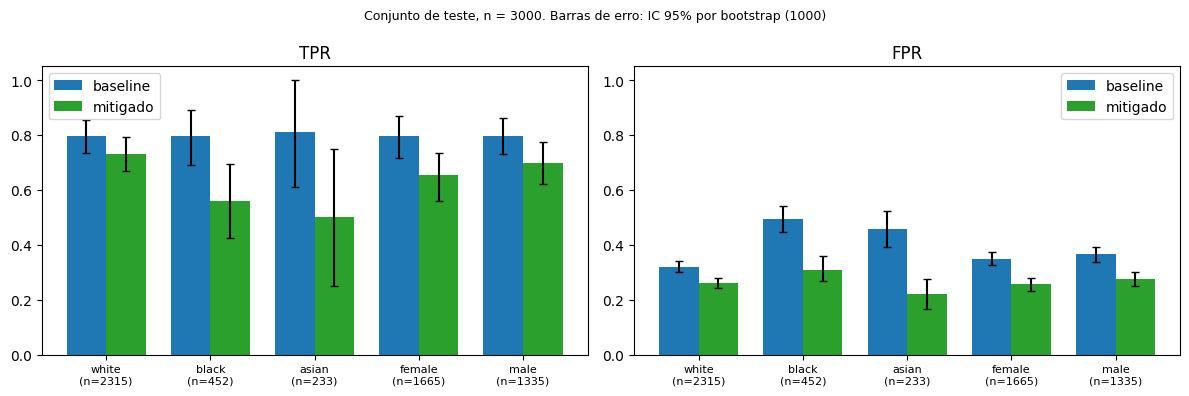

In [ ]:
def parse(s): lo, hi = s.strip("[]").split(";"); return float(lo), float(hi)
ordem_g = [("race", "white"), ("race", "black"), ("race", "asian"), ("gender", "female"), ("gender", "male")]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, met in zip(ax, ["TPR", "FPR"]):
    for j, (nome, cor) in enumerate([("baseline", "tab:blue"), ("mitigado", "tab:green")]):
        v, e = [], []
        for at, g in ordem_g:
            r = tab_g[(tab_g.modelo == nome) & (tab_g.atributo == at) & (tab_g.grupo == g)].iloc[0]
            lo, hi = parse(r[f"{met}_IC"]); v.append(r[met]); e.append([r[met] - lo, hi - r[met]])
        a.bar(np.arange(5) + j * 0.38, v, 0.38, yerr=np.array(e).T, capsize=3, color=cor, label=nome)
    a.set_xticks(np.arange(5) + 0.19)
    a.set_xticklabels([f"{g}\n(n={int(tab_g[(tab_g.atributo==at)&(tab_g.grupo==g)].n.iloc[0])})" for at, g in ordem_g], fontsize=8)
    a.set_title(met); a.set_ylim(0, 1.05); a.legend()
fig.suptitle("Conjunto de teste, n = 3000. Barras de erro: IC 95% por bootstrap (1000)", fontsize=9)
plt.tight_layout(); plt.savefig("/content/saidas/fig2_tpr_fpr_grupos.png", dpi=150); plt.show()

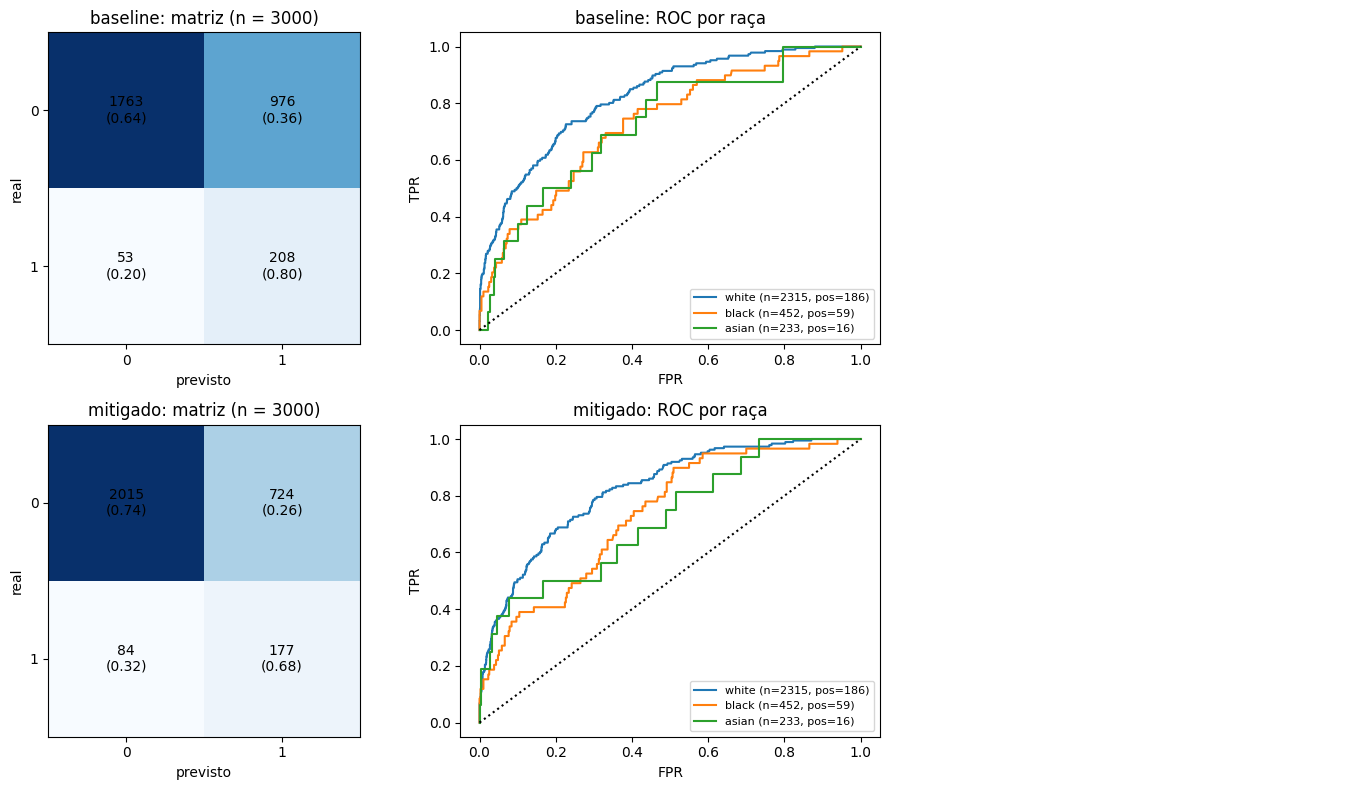

In [ ]:
from sklearn.metrics import roc_curve
fig, ax = plt.subplots(2, 3, figsize=(14, 8))
for i, nome in enumerate(["baseline", "mitigado"]):
    df = prd[nome]
    cm = confusion_matrix(df.y_true, df.y_pred)
    ax[i, 0].imshow(cm, cmap="Blues")
    for (r, c), v in np.ndenumerate(cm):
        ax[i, 0].text(c, r, f"{v}\n({v / cm[r].sum():.2f})", ha="center", va="center")
    ax[i, 0].set_xticks([0, 1]); ax[i, 0].set_yticks([0, 1])
    ax[i, 0].set_xlabel("previsto"); ax[i, 0].set_ylabel("real"); ax[i, 0].set_title(f"{nome}: matriz (n = 3000)")
    for g in ["white", "black", "asian"]:
        d = df[df.race == g]; f_, t_, _ = roc_curve(d.y_true, d.prob)
        ax[i, 1].plot(f_, t_, label=f"{g} (n={len(d)}, pos={int(d.y_true.sum())})")
    ax[i, 1].plot([0, 1], [0, 1], "k:"); ax[i, 1].set_title(f"{nome}: ROC por raça"); ax[i, 1].legend(fontsize=8)
    ax[i, 1].set_xlabel("FPR"); ax[i, 1].set_ylabel("TPR")
    ax[i, 2].axis("off")
plt.tight_layout(); plt.savefig("/content/saidas/fig1_matriz_roc.png", dpi=150); plt.show()

In [ ]:
def glob(df, b):
    y, pred, prob = df.y_true.values[b], df.y_pred.values[b], df.prob.values[b]
    tp = ((pred==1)&(y==1)).sum(); fp = ((pred==1)&(y==0)).sum()
    fn = ((pred==0)&(y==1)).sum(); tn = ((pred==0)&(y==0)).sum()
    pr, se = tp/(tp+fp), tp/(tp+fn)
    return {"AUROC": roc_auc_score(y, prob), "Sensibilidade": se, "Especificidade": tn/(tn+fp),
            "Precisão": pr, "F1": 2*pr*se/(pr+se)}

rows = []
for n in prd:
    o = glob(prd[n], todos); b_ = pd.DataFrame([glob(prd[n], b) for b in boot_idx])
    r = json.load(open(f"/content/saidas/resumo_{n}.json"))
    row = {"modelo": n, "limiar": round(limiares[n]["limiar"], 3)}
    for k, v in o.items():
        lo, hi = np.percentile(b_[k], [2.5, 97.5]); row[k] = f"{v:.3f} [{lo:.3f}; {hi:.3f}]"
    row.update(epocas=r["epocas_executadas"], melhor_epoca=r["melhor_epoca"], tempo_s=r["tempo_total_s"])
    rows.append(row)
tab2 = pd.DataFrame(rows); display(tab2)
tab2.to_csv("/content/saidas/tabelas/tabela2_global.csv", index=False)

,modelo,limiar,AUROC,Sensibilidade,Especificidade,Precisão,F1,epocas,melhor_epoca,tempo_s
0,baseline,0.114,0.804 [0.775; 0.831],0.797 [0.747; 0.847],0.644 [0.625; 0.661],0.176 [0.154; 0.199],0.288 [0.257; 0.320],12,7,325.3
1,mitigado,0.305,0.797 [0.769; 0.821],0.678 [0.620; 0.733],0.736 [0.718; 0.752],0.196 [0.170; 0.222],0.305 [0.269; 0.339],13,8,346.5


In [ ]:
from google.colab import drive
drive.mount("/content/drive")
!mkdir -p /content/drive/MyDrive/Artigo3/saidas
!cp -r /content/saidas/. /content/drive/MyDrive/Artigo3/saidas/
!ls /content/drive/MyDrive/Artigo3/saidas /content/drive/MyDrive/Artigo3/saidas/tabelas

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Artigo3/saidas:
curvas_treino.png	 log_mitigado.csv      splits
fig1_matriz_roc.png	 lote_conferencia.png  tabelas
fig2_tpr_fpr_grupos.png  predicoes	       teste_global.json
limiares.json		 resumo_baseline.json  versoes.txt
log_baseline.csv	 resumo_mitigado.json

/content/drive/MyDrive/Artigo3/saidas/tabelas:
divisao_x_classe.csv	   language_total.csv
ethnicity_por_divisao.csv  pesos_mitigado.csv
ethnicity_total.csv	   race_por_divisao.csv
gender_por_divisao.csv	   race_total.csv
gender_total.csv	   tabela2_global.csv
idade_por_classe.csv	   tabela3_gaps.csv
idade_por_raca.csv	   tabela3_por_grupo.csv
language_por_divisao.csv   tabela_comparacao_pareada.csv
